In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import plot_tree, DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from  sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import ( mean_absolute_error, root_mean_squared_error, r2_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, silhouette_score)
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (7, 5)

In [10]:
df = pd.read_csv('classical_ml_student_performance.csv')
df.shape
df.head()
df['Pass'].value_counts(normalize=True).round(3)
df.describe().round(2)

,Study_Hours,Attendance_pct,Previous_Marks,Assignment_Score,Sleep_Hours,Practice_Tests,Final_Marks,Pass
count,320.00,320.00,320.00,320.00,320.00,320.00,320.00,320.00
mean,7.71,73.82,65.40,70.27,6.63,4.77,59.78,0.54
std,3.28,13.09,14.42,14.91,0.93,2.56,17.63,0.50
min,1.00,40.00,30.00,30.00,4.50,0.00,20.00,0.00
25%,5.10,64.57,55.45,61.40,6.10,3.00,46.72,0.00
50%,7.80,74.20,65.55,71.50,6.60,5.00,61.10,1.00
75%,9.93,84.80,76.80,81.05,7.30,7.00,73.60,1.00
max,15.00,100.00,95.00,100.00,9.00,10.00,95.10,1.00


In [13]:
feature_cols = ['Study_Hours', 'Attendance_pct', 'Previous_Marks', 'Assignment_Score', 'Sleep_Hours', 'Practice_Tests']

paper10 = df.loc[:9,['Student_ID'] +feature_cols + ['Final_Marks', 'Pass'] ]
paper10

,Student_ID,Study_Hours,Attendance_pct,Previous_Marks,Assignment_Score,Sleep_Hours,Practice_Tests,Final_Marks,Pass
0,S001,12.2,79.7,83.1,89.2,6.4,7,93.2,1
1,S002,11.8,55.7,30.0,77.9,6.4,6,61.8,1
2,S003,13.4,98.3,66.2,96.3,6.1,6,86.3,1
3,S004,9.0,95.4,70.5,86.5,5.5,6,64.9,1
4,S005,8.0,58.4,56.8,53.5,6.0,4,44.3,0
5,S006,11.9,73.4,70.7,87.0,6.6,2,79.9,1
6,S007,12.7,84.8,74.3,79.0,7.5,10,77.3,1
7,S008,10.4,85.0,91.0,84.2,7.6,2,68.4,1
8,S009,4.6,60.3,47.2,50.8,6.5,1,38.2,0
9,S010,6.5,66.1,88.4,88.2,7.0,7,65.7,1


In [22]:
#now practicing after doing by hand
manual = df.iloc[:5]
x = manual['Study_Hours'].to_numpy()
y = manual['Final_Marks'].to_numpy()

x_mean, y_mean = x.mean(), y.mean()

w = np.sum((x-x_mean)*(y-y_mean)) / np.sum((x-x_mean)**2)
w
c = y_mean - w*x_mean
c

#prediction model
w*8 + c

49.6093990755008

In [ ]:
#now by using sklearn linear regression
x_simple = df[['Study_Hours']]
y_reg = df['Final_Marks']

#using train test split
x_train, x_test, y_train, y_test = train_test_split(x_simple, y_reg, random_state=42, test_size=0.20)

lr_model = LinearRegression()
lr_model.fit(x_train, y_train)

y_predict = lr_model.predict(x_test)

print('gradient:', lr_model.coef_[0])
print('Intercept:', lr_model.intercept_)
#errors
print('mean absolute error: ', mean_absolute_error(y_test, y_predict))
print('mean squared error: ', root_mean_squared_error(y_test, y_predict))
print('r2 score: ', r2_score(y_test, y_predict)) # tell how well our model peform on unseen real world data a percentage 0.78 or 78%



gradient: 4.658451127716661
Intercept: 23.92131331141229
mean absolute error:  6.701029473883294
mean squared error:  8.423701234624717
r2 score:  0.7773437881376936


C:\Users\laiba Rasheed\AppData\Roaming\Python\Python312\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


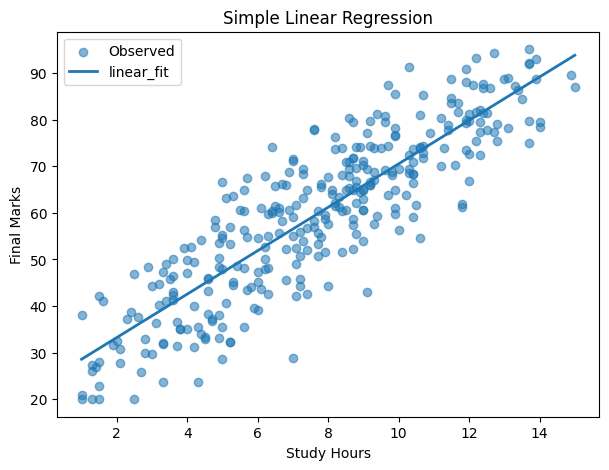

In [37]:
#time to make a scatter plot

plt.scatter(df['Study_Hours'], df['Final_Marks'], alpha=0.55, label= 'Observed')
x_line = np.linspace(df['Study_Hours'].min(), df['Study_Hours'].max(), 100). reshape(-1,1)
plt.plot(x_line, lr_model.predict(x_line), linewidth=2, label= 'linear_fit')

plt.xlabel('Study Hours')
plt.ylabel('Final Marks')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

In [52]:
# now will doing multiple linear regression to get more accurate predictions
#now we have multiple x's in feature columns

X = df[feature_cols]
X_train, X_test, Y_train,Y_test = train_test_split(X, y_reg, random_state=42, test_size=0.20)

# now we will train
multiple_lr = LinearRegression()

multiple_lr.fit(X_train,Y_train)

y_predict_multi = mulitple_lr.predict(X_test)

#now we will agian check our metric will form a resultatn table
coef_table = pd.DataFrame({
    'Features': feature_cols, 
    'Coefficient': multiple_lr.coef_
})
print(coef_table.sort_values(by='Coefficient', key=abs ,ascending=False)) # abs mean sort on postivie values.

#intercept
print('multi regression intercept: ', round(multiple_lr.intercept_,3))
#errors:
print('mean absolute error: ', round(mean_absolute_error(Y_test, y_predict_multi),3))
print('mean squared error: ', round(root_mean_squared_error(Y_test, y_predict_multi),3))
print('r2 score: ', round(r2_score(Y_test, y_predict_multi),3))

           Features  Coefficient
0       Study_Hours     2.783904
4       Sleep_Hours     0.805575
5    Practice_Tests     0.637448
3  Assignment_Score     0.228201
2    Previous_Marks     0.204492
1    Attendance_pct     0.169851
multi regression intercept:  -12.106
mean absolute error:  5.237
mean squared error:  6.336
r2 score:  0.874


In [ ]:
#plotting
